# A/B Experiment on a Landing Page

The goal of this project is to evaluate an **A/B experiment** run on a landing page with versions **A and B**, in order to support a **data-driven business decision**.

---

The file `landing_experiment.csv` contains data on users exposed to two versions of the landing page within the A/B experiment. It includes region, device, traffic source, user type, conversion and spend.

The analysis follows a clear, progressive logic:

1. Explore and validate the data.
2. Compare the **average spend** per user between page A and page B.
3. Compare the **conversion rate** between page A and page B.
4. Review **the relationship between traffic source and conversion**.
5. Review **the relationship between user type and conversion**.
6. **Visualize the results** with clear charts that support the conclusions.
7. Summarize the findings in an **executive insight** with recommendations.

**Appropriate statistical tests** are applied to compare the pages and **recommend which version is better**, justifying the decision with data.

## Step 1. Load and validate the data

### 1.1 Data loading and quick look

The necessary libraries are imported (`pandas`, `scipy`, `statsmodels`, `matplotlib` and `seaborn`) and the file `landing_experiment.csv` is loaded into the DataFrame `df`. The first rows and the general information of the dataset are reviewed to confirm that it loaded correctly and to learn its columns and data types.

In [1]:
# Import libraries
import pandas as pd
from scipy import stats
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the file
df = pd.read_csv('/datasets/landing_experiment.csv')

**Preview and general information of the dataset**

In [3]:
# Show the first 5 rows
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# General information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Observations**
- No null values are observed.
- The `date` column is of type `object` and must be converted to `datetime`.

In [5]:
df['date'] = pd.to_datetime(df['date'])

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


**Dataset description**

The dataset contains the following columns:

- `user_id`: unique user identifier.
- `date`: date on which the user was exposed to the page.
- `landing`: version of the page shown to the user.
- `region`: user's geographic region.
- `dispositivo`: type of device used by the user.
- `traffic_source`: channel through which the user arrived.
- `user_type`: type of user based on prior history.
- `converted`: indicates whether the user made a conversion.
- `gasto`: amount spent by the user (0 if the user did not convert).

### 1.2 Exploratory analysis and data quality review

The key variables of the A/B experiment are identified, and the data is validated to confirm that it is well defined, complete and consistent.

**Variable `user_id`:** it is verified that users are unique.

In [7]:
df["user_id"].nunique()

40000

There are 40,000 unique identifiers for 40,000 rows: each row corresponds to a different user.

**Variable `date`:** the date range of the experiment is explored.

In [8]:
# Statistical summary
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [9]:
# Identify the time range of the experiment
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


The experiment covers 28 days, from January 1 to January 28, 2026.

**Variable `gasto` (numeric):** the statistical summary is reviewed for all users and for those who converted.

In [10]:
# Statistical summary
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [11]:
# Statistical summary of users who converted
df[df["converted"]==1]["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

The median of `gasto` is 0 because most users did not convert. Among the 5,706 users who converted, the average spend is 65.37, with a minimum of 12.12 and a maximum of 303.68.

**Categorical variables:** the expected categories of the experiment (A and B) are verified, along with the distribution of the rest.

In [12]:
# Explore categorical variables and how they are distributed
print("\nConteo de categorías:")
columnas_categoricas = ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']

for col in columnas_categoricas:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


Conteo de categorías:

--- landing ---
B    20018
A    19982
Name: landing, dtype: int64

--- region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

--- dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

--- traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

--- user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


- All columns have expected values.
- Assignment to the pages is practically balanced: 19,982 users on page A and 20,018 users on page B.

## Step 2. Compare the average spend per user (page A vs. B)

This step evaluates whether there are statistically significant differences in the average spend of the **users who became customers** between page A and page B, in order to identify which version generates **greater economic value** for the business.

In [13]:
# Spend by version
gasto_A =  df[(df['converted']==1) & (df['landing']=='A')]['gasto']
gasto_B = df[(df['converted']==1) & (df['landing']=='B')]['gasto']

# Check the number of records in each group
len(gasto_A), len(gasto_B)

(2512, 3194)

In [14]:
# Average spend by version
print(f"Gasto promedio página A: {gasto_A.mean():.2f}")
print(f"Gasto promedio página B: {gasto_B.mean():.2f}")
print(f"\nMediana página A: {gasto_A.median():.2f}")
print(f"Mediana página B: {gasto_B.median():.2f}")

Gasto promedio página A: 61.09
Gasto promedio página B: 68.75

Mediana página A: 55.84
Mediana página B: 62.57


### Test

**Hypotheses:**
- **Null hypothesis (H₀):** there is no significant difference in average spend between converted users on page A and converted users on page B.
- **Alternative hypothesis (H₁):** there is a significant difference in average spend between converted users on page A and converted users on page B.

First, the equality of variances is checked with Levene's test, and depending on its result, the independent two-sample t-test is applied.

In [15]:

# Apply the test

# Check the equality of variances first
stat_levene, p_levene = stats.levene(gasto_A, gasto_B)
print(f"Test de Levene - p-value: {p_levene:.4f}")

equal_var = p_levene >= 0.05  # True if the variances are similar

t_stat, p_value = stats.ttest_ind(gasto_A, gasto_B, equal_var=equal_var)

# Display results
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.4f}")

Test de Levene - p-value: 0.0000
Estadístico t: -9.4810
Valor p: 0.0000


In [16]:
alpha = 0.05
if p_value < alpha:
    print(f"Se rechaza H₀ (p={p_value:.4f} < {alpha})")
    print("Existe una diferencia estadísticamente significativa en el gasto promedio entre página A y B")
else:
    print(f"No se rechaza H₀ (p={p_value:.4f} >= {alpha})")
    print("No hay evidencia suficiente de diferencia significativa en el gasto promedio entre página A y B")

Se rechaza H₀ (p=0.0000 < 0.05)
Existe una diferencia estadísticamente significativa en el gasto promedio entre página A y B


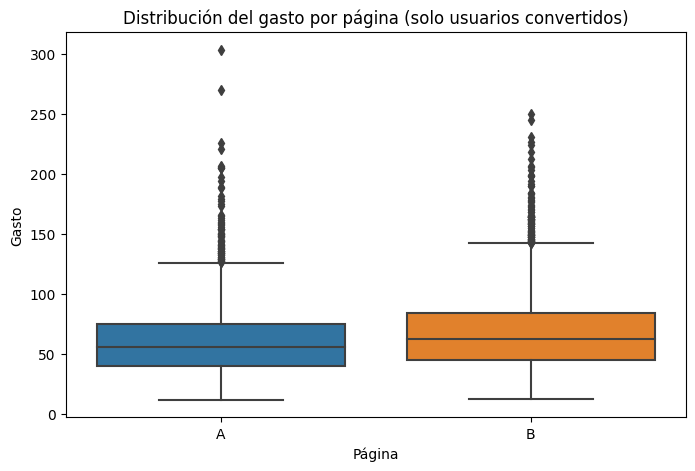

In [17]:

plt.figure(figsize=(8,5))
sns.boxplot(x='landing', y='gasto', data=df[df['converted']==1])
plt.title('Distribución del gasto por página (solo usuarios convertidos)')
plt.xlabel('Página')
plt.ylabel('Gasto')
plt.show()

### Conclusion and interpretation

**Decision:** the null hypothesis (H₀) is rejected, since the p-value obtained (p < 0.0001) is lower than the established significance level (0.05). This indicates that there is a statistically significant difference in average spend between converted users on page A and converted users on page B.

**Business interpretation:** users who converted through page B spent 68.75 on average, 12.5% more than users who converted through page A (61.09). Since this difference is statistically significant, page B generates greater economic value per converted user. This suggests that, beyond the conversion rate, page B may be attracting a customer profile with a higher willingness to spend, or that its design or purchase flow favors larger tickets. Prioritizing page B as the main version is recommended, complementing this finding with the analysis of the conversion rate by page to get a full picture of the impact on total revenue.

## Step 3. Compare the conversion rate between page A and B

This step evaluates whether there are statistically significant differences in the **conversion rate** between page A and B, in order to identify which version generates the **greater number of converted users**.

### Test

**Hypotheses:**
- **Null hypothesis (H₀):** there is no significant difference in the conversion rate between page A and page B.
- **Alternative hypothesis (H₁):** there is a significant difference in the conversion rate between page A and page B.

The number of converted users and the total number of users per page are counted, the conversion rate of each is calculated, and a two-proportion z-test is applied.

In [18]:
# Number of converted users per page
convertidos_por_pagina = df[df['converted']==1]['landing'].value_counts()

# Total number of users per page
total_por_pagina = df['landing'].value_counts()

print("Usuarios convertidos por página:\n", convertidos_por_pagina)
print("\nTotal de usuarios por página:\n", total_por_pagina)


Usuarios convertidos por página:
 B    3194
A    2512
Name: landing, dtype: int64

Total de usuarios por página:
 B    20018
A    19982
Name: landing, dtype: int64


In [19]:
tasa_A = convertidos_por_pagina['A'] / total_por_pagina['A']
tasa_B = convertidos_por_pagina['B'] / total_por_pagina['B']

print(f"Tasa de conversión página A: ({tasa_A*100:.2f}%)")
print(f"Tasa de conversión página B: ({tasa_B*100:.2f}%)")

Tasa de conversión página A: (12.57%)
Tasa de conversión página B: (15.96%)


In [20]:

# Apply the test
exitos = [convertidos_por_pagina['A'], convertidos_por_pagina['B']]
n_obs = [total_por_pagina['A'], total_por_pagina['B']]

z_stat, p_value = proportions_ztest(exitos, n_obs)

# Display results
print(f"Estadístico z: {z_stat:.4f}")
print(f"Valor p: {p_value:.4f}")

Estadístico z: -9.6774
Valor p: 0.0000


### Conclusion and interpretation

**Decision:** the null hypothesis (H₀) is rejected, since the p-value obtained (p < 0.0001) is lower than the established significance level (0.05). This indicates that there is a statistically significant difference in the conversion rate between page A and page B.

**Business interpretation:** page B has a conversion rate of 15.96%, higher than that of page A (12.57%), a difference of 3.39 percentage points. This difference is statistically significant: page B outperforms page A both in conversion volume and in economic value per conversion. This reinforces the recommendation to prioritize page B as the main version, since it delivers a double benefit: more converted users and a higher average spend among those who convert.

## Step 4. Review the relationship between traffic source and conversion

This step analyzes whether there is a **statistically significant association** between the **traffic source** (`traffic_source`) and **conversion** (`converted`), in order to identify which channels generate the most conversions.

### Test

**Hypotheses:**
- **Null hypothesis (H₀):** there is no significant relationship between traffic source and conversion.
- **Alternative hypothesis (H₁):** there is a significant relationship between traffic source and conversion.

The contingency table between both variables is built and the chi-square test of independence is applied. The normalized table is then displayed to see each channel's conversion rate.

In [21]:
tabla_contingencia = pd.crosstab(df['traffic_source'], df['converted'])
print(tabla_contingencia)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [22]:

# Apply the test
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_contingencia)

print(f"Estadístico Chi2: {chi2_stat:.4f}")
print(f"Valor p: {p_value:.4f}")

Estadístico Chi2: 8.6621
Valor p: 0.0341


In [23]:

# Interpret results
alpha = 0.05  # significance threshold

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

print()  # blank line

# Normalized contingency table
print(pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100)

Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


### Conclusion and interpretation

**Decision:** the null hypothesis (H₀) is rejected, since the p-value obtained (0.0341) is lower than the established significance level (0.05). This indicates that there is a statistically significant association between traffic source and conversion.

**Business interpretation:** although the association is statistically significant, the size of the difference between channels is small: conversion rates fall in a narrow range, from 13.79% (Organic) to 14.99% (Email), a difference of only 1.2 percentage points between the most and least effective channel. Email and Ads show the highest conversion rates (14.99% and 14.74%, respectively), while Organic and Referral are slightly lower (13.79% and 13.88%). However, Organic is the channel that contributes the most converted users (2,480), simply because it is the source with the highest traffic volume.

## Step 5. Review the relationship between user type and conversion

This step analyzes whether there is a **statistically significant association** between **user type** (`user_type`) and **conversion** (`converted`), bearing in mind that a returning user may have visited before without necessarily becoming a customer on this occasion.

The goal is to identify which profiles show a higher probability of converting within the analyzed context.

### Test

**Hypotheses:**
- **Null hypothesis (H₀):** there is no significant relationship between user type and conversion.
- **Alternative hypothesis (H₁):** there is a significant relationship between user type and conversion.

The contingency table is built, the conversion rate of each user type is calculated, and the chi-square test of independence is applied.

In [24]:
tabla_contingencia_user = pd.crosstab(df['user_type'], df['converted'])
print(tabla_contingencia_user)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [25]:
tasas_user_type = df.groupby('user_type')['converted'].mean()
print(tasas_user_type)

user_type
Nuevo         0.143587
Recurrente    0.140904
Name: converted, dtype: float64


In [26]:
# Apply the test
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_contingencia_user)

print(f"Estadístico Chi2: {chi2_stat:.4f}")
print(f"Valor p: {p_value:.4f}")


Estadístico Chi2: 0.5135
Valor p: 0.4736


In [27]:
# Interpret results
alpha = 0.05  # significance threshold

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

print()  # blank line

# Normalized contingency table
print(pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100)

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


### Conclusion and interpretation

**Decision:** the null hypothesis (H₀) is not rejected, since the p-value obtained (0.4736) is higher than the established significance level (α = 0.05). This indicates that there is not enough statistical evidence to claim an association between user type and conversion.

**Business interpretation:** the conversion rates of new users (14.36%) and returning users (14.09%) are practically identical, a difference of only 0.27 percentage points that, in addition, was not statistically significant. This indicates that, within this experiment, whether a user is new or returning does not influence their probability of converting.

## Step 6. Visualize the results for categorical variables

The relationship between the categorical variables (`traffic_source` and `user_type`) and conversion is explored visually, showing for each category:
- the absolute number of users who converted and did not convert,
- the proportion of users who converted and did not convert.

This makes it possible to analyze both the impact in volume and the relative effectiveness of each category, and to reinforce the results obtained in the statistical tests.

### Relationship between traffic source and conversion

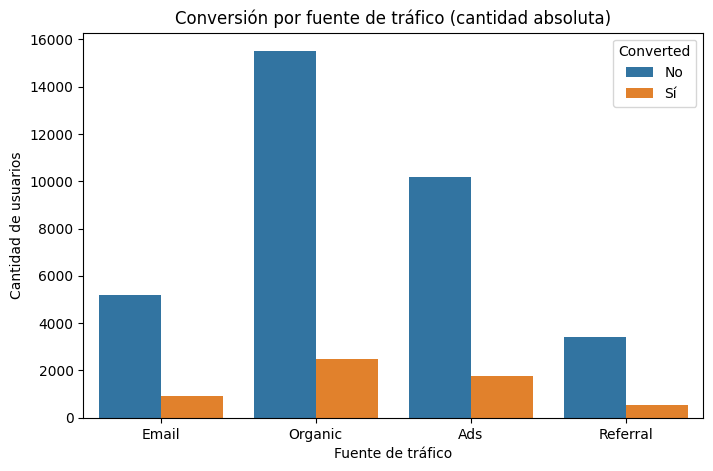

In [28]:
# Absolute number of converted and non-converted users by traffic source
plt.figure(figsize=(8,5))
sns.countplot(x='traffic_source', hue='converted', data=df)
plt.title('Conversión por fuente de tráfico (cantidad absoluta)')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Converted', labels=['No', 'Sí'])
plt.show()

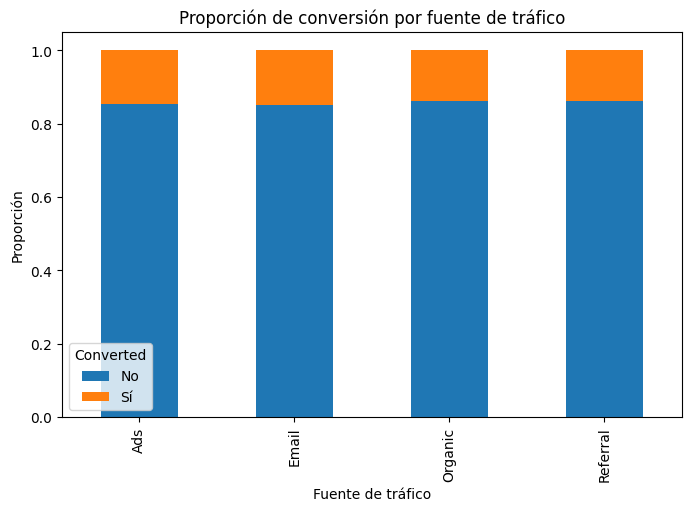

In [29]:
# Proportion of converted and non-converted users by traffic source
prop_traffic = pd.crosstab(df['traffic_source'], df['converted'], normalize='index')
prop_traffic.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title('Proporción de conversión por fuente de tráfico')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Proporción')
plt.legend(title='Converted', labels=['No', 'Sí'])
plt.show()

In terms of converted users, Organic contributes the largest absolute number (2,480), followed by Ads (1,759), Email (918) and Referral (549), an order that mainly reflects the volume of each channel and not its effectiveness. In the proportions chart, the four orange bars (conversion) look very similar in height, with no channel clearly dominating.

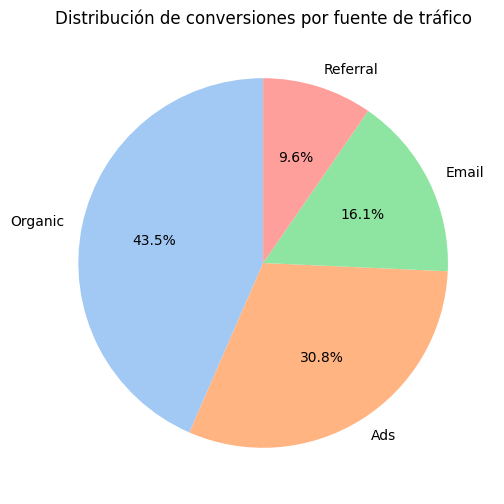

In [30]:

convertidos_traffic = df[df['converted']==1]['traffic_source'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(convertidos_traffic, labels=convertidos_traffic.index, autopct='%1.1f%%',
        colors=sns.color_palette('pastel'), startangle=90)
plt.title('Distribución de conversiones por fuente de tráfico')
plt.show()

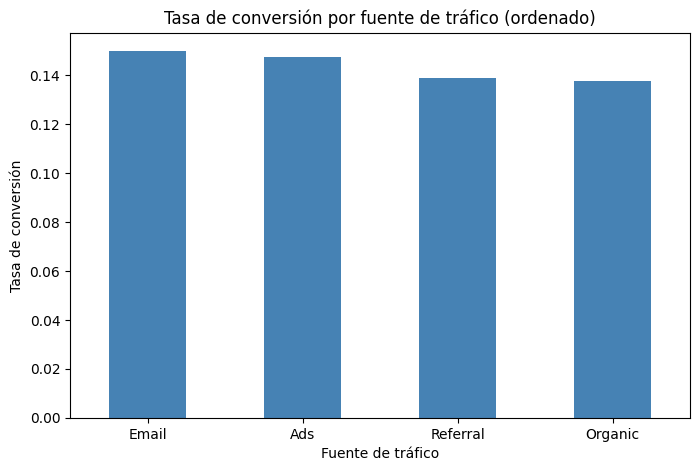

In [31]:

# Conversion rate sorted from highest to lowest
tasa_traffic = df.groupby('traffic_source')['converted'].mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
tasa_traffic.plot(kind='bar', color='steelblue')
plt.title('Tasa de conversión por fuente de tráfico (ordenado)')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Tasa de conversión')
plt.xticks(rotation=0)
plt.show()

The pie chart shows that, of all conversions, 43.5% come from Organic and 30.8% from Ads: together they account for almost three quarters of all converted customers, simply because of their higher traffic volume. Email contributes 16.1% and Referral only 9.6%. It is important not to confuse this distribution (where customers come from in absolute terms) with the conversion rate per channel (how effective each channel is proportionally): Organic brings in more customers overall, but Email has the highest conversion rate (14.99% vs. 13.79% for Organic). This has a clear business implication: if the goal is to maximize volume, Organic is indispensable; if the goal is to maximize efficiency per visitor, Email deserves relatively more investment.

### Relationship between user type and conversion

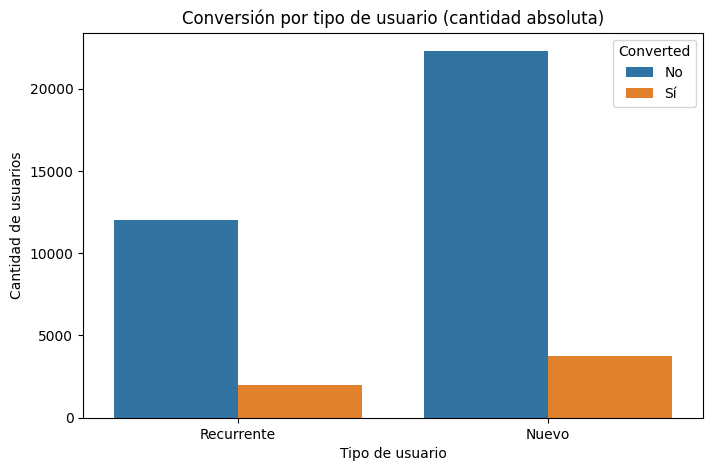

In [32]:
plt.figure(figsize=(8,5))
sns.countplot(x='user_type', hue='converted', data=df)
plt.title('Conversión por tipo de usuario (cantidad absoluta)')
plt.xlabel('Tipo de usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Converted', labels=['No', 'Sí'])
plt.show()

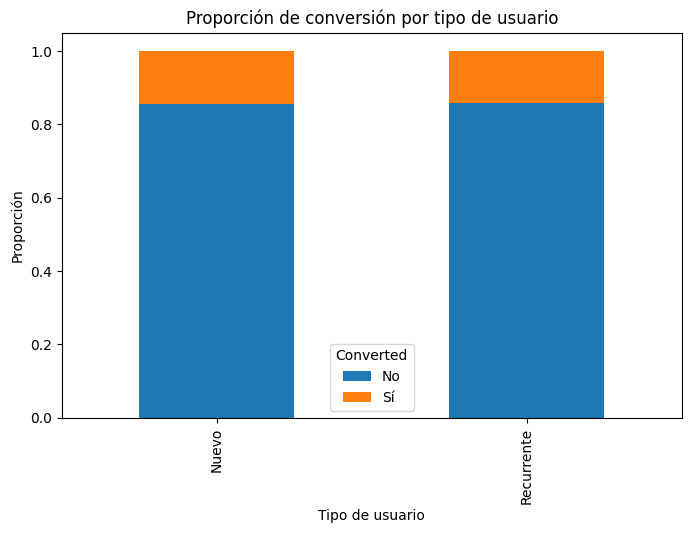

In [33]:
prop_user = pd.crosstab(df['user_type'], df['converted'], normalize='index')
prop_user.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title('Proporción de conversión por tipo de usuario')
plt.xlabel('Tipo de usuario')
plt.ylabel('Proporción')
plt.legend(title='Converted', labels=['No', 'Sí'])
plt.show()

"New" users represent almost double the volume of "Returning" users (26,033 vs. 13,967), which is reflected in much taller absolute bars for that group. However, when looking at the conversion proportions, both bars look practically identical: there is no perceptible visual difference between segments. This is consistent with the result of Step 5, where the chi-square test found no evidence of association (p = 0.4736): user type does not appear to influence the probability of conversion within this experiment.

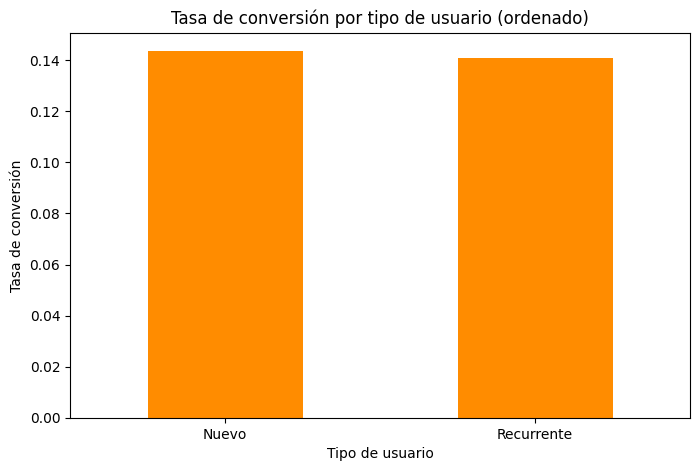

In [34]:

tasa_user = df.groupby('user_type')['converted'].mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
tasa_user.plot(kind='bar', color='darkorange')
plt.title('Tasa de conversión por tipo de usuario (ordenado)')
plt.xlabel('Tipo de usuario')
plt.ylabel('Tasa de conversión')
plt.xticks(rotation=0)
plt.show()

The rates chart confirms what the previous charts already suggested: 14.36% for new users vs. 14.09% for returning users, a minimal difference of only 0.27 percentage points. Unlike `traffic_source`, where there was an association (albeit a weak one), here there is not even that: user type is not a useful variable for segmenting conversion strategies in this experiment.

## Step 7. Executive insight for stakeholders

The findings of the A/B experiment analysis are translated into actionable conclusions for the business, focused on **page version, conversion, average spend, traffic channels and user type**.

### Executive insight based on the A/B experiment

#### Page comparison (A vs. B)

**Average spend per user who converted**
- **Observation 1:** page B has an average spend of 68.75, compared with 61.09 for page A: a difference of 7.66 (12.5% higher).
- **Observation 2:** the difference is statistically significant (t = -9.48, p < 0.0001), so it is not explained by chance.
- **Interpretation:** users who convert on page B consistently spend more than those on page A. This suggests that B's design or purchase flow favors larger tickets, generating greater economic value for each converted customer.

**Conversion rate**
- **Observation 1:** page B converts 15.96% of its users, compared with 12.57% for page A: a difference of 3.39 percentage points.
- **Observation 2:** the difference is statistically significant (z = -9.68, p < 0.0001), confirming that it is not the product of chance.
- **Interpretation:** page B not only generates more revenue per conversion, it also converts more users in the first place. It is the variable with the strongest and most consistent impact in the whole analysis, outperforming page A on both key dimensions.

---

#### Segmentation by traffic source

- **Observation:** among converted users, Organic contributes the largest absolute number (2,480), followed by Ads (1,759), Email (918) and Referral (549). However, in conversion rate, Email (14.99%) and Ads (14.74%) slightly outperform Organic (13.79%) and Referral (13.88%): a difference of only 1.2 percentage points between the most and least effective channel, although statistically significant (χ² = 8.66, p = 0.0341).
- **Interpretation:** traffic source has a real but marginal influence on conversion, far below the impact of the page version. Organic remains strategically key because it contributes the highest absolute volume of customers, while Email stands out for its relative efficiency per visitor.

---

#### Segmentation by user type

- **Observation:** new users convert at 14.36% and returning users at 14.09%: a minimal difference of 0.27 percentage points, which was not statistically significant (χ² = 0.51, p = 0.4736).
- **Interpretation:** a user's prior history (new vs. returning) does not influence their probability of converting within this experiment. There is no justification for differentiating marketing strategies by this criterion.

---

The visualizations used support the statistical results of the previous steps.

---

#### Business recommendations

- **Migrate to page B as the main version of the site.** It is the factor with the strongest, most consistent and most actionable impact in the whole analysis: it improves both the number of conversions and the economic value of each one.
- **Prioritize investment in Email and Ads as acquisition channels**, since they show relatively higher conversion rates, while continuing to sustain Organic for its dominant volume of traffic and total conversions.
- **There is no need to design differentiated campaigns or experiences by user type** (new vs. returning), since there is no evidence that this factor influences conversion. Personalization resources can be redirected to other variables with proven impact, such as the page version.
- **Deepen the analysis of `traffic_source` with a larger sample or a longer period**, since although the association is significant, its size is small and more data could help confirm whether the pattern holds over time.